<a href="https://colab.research.google.com/github/cleberfmodesto/classificacao_xgboost/blob/main/Aulas/Aula_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Classificação: melhorando o desempenho com XGBoost**

##**Aula 1 - Conhecendo os dados**

###**Importando os dados**

In [1]:
url = 'https://raw.githubusercontent.com/alura-cursos/classificacao_xgboost/main/Dados/doenca_cardiaca.csv'

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(url)

In [4]:
df.head()

,Idade,Sexo,Tipo dor,Pressao arterial,Colesterol,Glicemia jejum >120,Resultados ECG,Frequencia cardiaca max,Dor exercicio,Depressao ST,Inclinacao ST,Numero vasos fluro,Teste cintilografia,Doenca cardiaca
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presenca
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Ausencia
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presenca
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Ausencia
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Ausencia


###**Explorando os dados**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Idade                    270 non-null    int64  
 1   Sexo                     270 non-null    int64  
 2   Tipo dor                 270 non-null    int64  
 3   Pressao arterial         270 non-null    int64  
 4   Colesterol               270 non-null    int64  
 5   Glicemia jejum >120      270 non-null    int64  
 6   Resultados ECG           270 non-null    int64  
 7   Frequencia cardiaca max  270 non-null    int64  
 8   Dor exercicio            270 non-null    int64  
 9   Depressao ST             270 non-null    float64
 10  Inclinacao ST            270 non-null    int64  
 11  Numero vasos fluro       270 non-null    int64  
 12  Teste cintilografia      270 non-null    int64  
 13  Doenca cardiaca          270 non-null    object 
dtypes: float64(1), int64(12), 

In [6]:
import seaborn as sns

<Axes: xlabel='Doenca cardiaca', ylabel='Idade'>

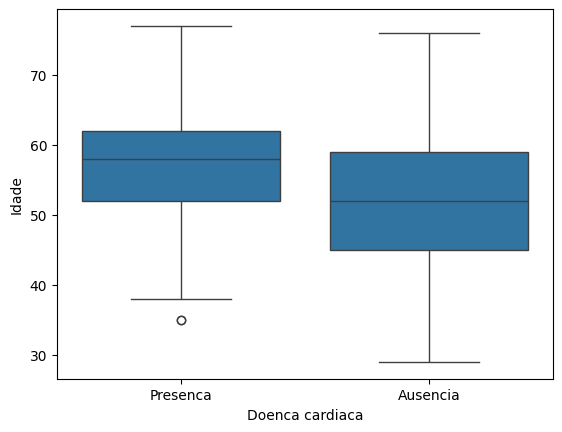

In [7]:
sns.boxplot(x='Doenca cardiaca', y='Idade', data=df)

<Axes: xlabel='Sexo', ylabel='count'>

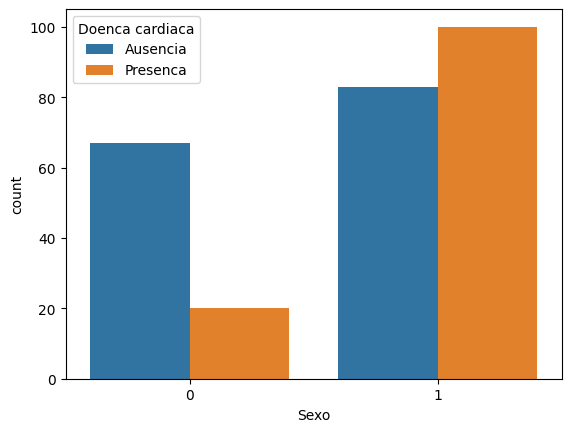

In [8]:
sns.countplot(x='Sexo', hue='Doenca cardiaca', data=df)

<Axes: xlabel='Tipo dor', ylabel='count'>

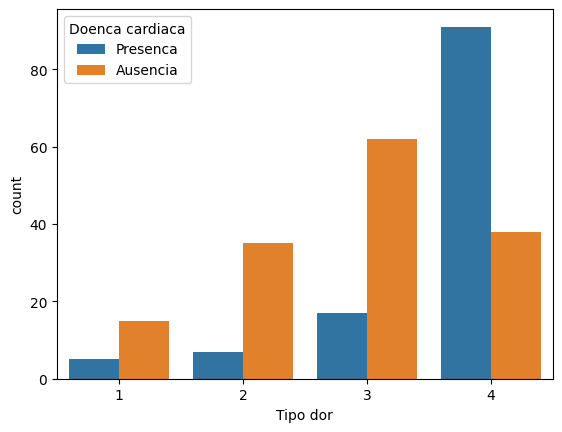

In [9]:
sns.countplot(x='Tipo dor', hue='Doenca cardiaca', data=df)

In [10]:
df['Doenca cardiaca'].value_counts()

Doenca cardiaca
Ausencia    150
Presenca    120
Name: count, dtype: int64

In [11]:
df['Doenca cardiaca'] = df['Doenca cardiaca'].map({'Presenca': 1, 'Ausencia': 0})

In [12]:
df

,Idade,Sexo,Tipo dor,Pressao arterial,Colesterol,Glicemia jejum >120,Resultados ECG,Frequencia cardiaca max,Dor exercicio,Depressao ST,Inclinacao ST,Numero vasos fluro,Teste cintilografia,Doenca cardiaca
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,0
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,0
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,0
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,0


##**Aula 2 - Iniciando a classificação**

###**Separando os dados**

In [13]:
X, y = df.iloc[:, :-1], df.iloc[:, -1]

In [14]:
from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

###**Classificando com Decision Tree**

In [15]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=0)

dt.fit(X_treino, y_treino)

preds = dt.predict(X_teste)

from sklearn.metrics import accuracy_score

acuracia = accuracy_score(y_teste, preds)
print(f'Acuracia: {acuracia:.2f}')

Acuracia: 0.76


###**Analisando as métricas do Decision Tree**

In [16]:
from sklearn.metrics import classification_report

report = classification_report(y_teste, preds)
print(report)

              precision    recall  f1-score   support

           0       0.81      0.73      0.77        30
           1       0.70      0.79      0.75        24

    accuracy                           0.76        54
   macro avg       0.76      0.76      0.76        54
weighted avg       0.77      0.76      0.76        54



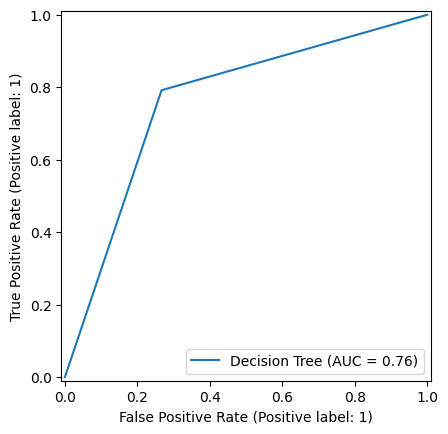

In [17]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_teste, preds, name='Decision Tree');

###**Classificando com XGBoost**

In [18]:
import xgboost as xgb

In [19]:
xg_cl = xgb.XGBClassifier(objective='binary:logistic')
xg_cl.fit(X_treino, y_treino)
preds = xg_cl.predict(X_teste)

acuracia = accuracy_score(y_teste, preds)
print(f'Acuracia: {acuracia:.2f}')

Acuracia: 0.81


###**Analisando as métricas do XGBoost**

In [20]:
report = classification_report(y_teste, preds)
print(report)

              precision    recall  f1-score   support

           0       0.86      0.80      0.83        30
           1       0.77      0.83      0.80        24

    accuracy                           0.81        54
   macro avg       0.81      0.82      0.81        54
weighted avg       0.82      0.81      0.82        54



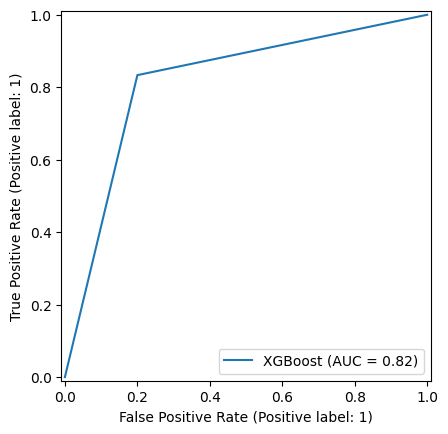

In [21]:
RocCurveDisplay.from_predictions(y_teste, preds, name='XGBoost');

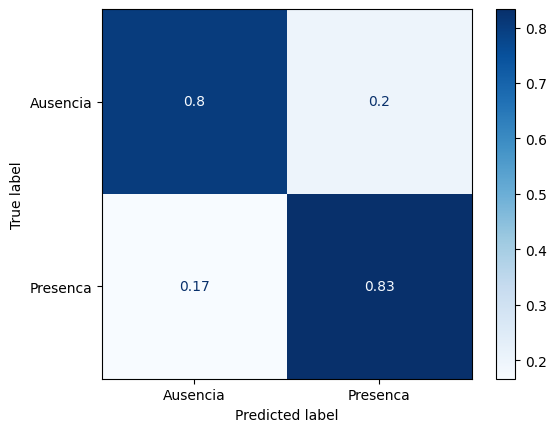

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(xg_cl, X_teste, y_teste, display_labels=['Ausencia', 'Presenca'],
                                      normalize='true', cmap='Blues');

##**Aula 3 - Realizando a validação cruzada**

###**Aplicando a validação cruzada**

In [23]:
dmatrix = xgb.DMatrix(data=X, label=y)

In [24]:
params = {'objective': 'binary:logistic'}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3, num_boost_round=5, metrics='error',
                       as_pandas=True, seed=123)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')

   train-error-mean  train-error-std  test-error-mean  test-error-std
0          0.138889         0.023570         0.288889        0.055184
1          0.081481         0.010476         0.262963        0.010476
2          0.068519         0.013858         0.248148        0.037771
3          0.050000         0.007857         0.229630        0.010476
4          0.046296         0.010476         0.225926        0.022831
Acuracia: 0.774074074074074


###**Explorando a técnica de Early Stopping**

In [25]:
params = {'objective': 'binary:logistic'}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3, num_boost_round=50, metrics='error',
                       as_pandas=True, seed=123)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')

    train-error-mean  train-error-std  test-error-mean  test-error-std
0           0.138889         0.023570         0.288889        0.055184
1           0.081481         0.010476         0.262963        0.010476
2           0.068519         0.013858         0.248148        0.037771
3           0.050000         0.007857         0.229630        0.010476
4           0.046296         0.010476         0.225926        0.022831
5           0.033333         0.013608         0.214815        0.013858
6           0.024074         0.006929         0.207407        0.013858
7           0.022222         0.007857         0.225926        0.010476
8           0.020370         0.009443         0.218519        0.005238
9           0.016667         0.004536         0.225926        0.013858
10          0.014815         0.005238         0.218519        0.010476
11          0.012963         0.006929         0.218519        0.013858
12          0.012963         0.006929         0.218519        0.010476
13    

In [26]:
params = {'objective': 'binary:logistic'}

cv_resultados = xgb.cv(dtrain=dmatrix, params=params, nfold=3, num_boost_round=100, early_stopping_rounds=5,
                       metrics='error', as_pandas=True, seed=123)

print(cv_resultados)
acuracia = 1 - cv_resultados['test-error-mean'].iloc[-1]
print(f'Acuracia: {acuracia}')

   train-error-mean  train-error-std  test-error-mean  test-error-std
0          0.138889         0.023570         0.288889        0.055184
1          0.081481         0.010476         0.262963        0.010476
2          0.068519         0.013858         0.248148        0.037771
3          0.050000         0.007857         0.229630        0.010476
4          0.046296         0.010476         0.225926        0.022831
5          0.033333         0.013608         0.214815        0.013858
6          0.024074         0.006929         0.207407        0.013858
Acuracia: 0.7925925925925926
